In [1]:
import supervision as sv


In [2]:
ds = sv.DetectionDataset.from_coco(images_directory_path="Dataset/image", annotations_path="Dataset/_annotations.coco.json")

In [3]:
len(ds)

15000

In [4]:
ds_train, ds = ds.split(split_ratio=0.7, shuffle=True, random_state=42)
ds_valid, ds_test = ds.split(split_ratio=0.5, shuffle=True, random_state=42)

In [5]:
len(ds_train), len(ds_valid), len(ds_test)

(10500, 2250, 2250)

In [12]:
box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

annotated_images = []
for i in range(16):
    _, image, annotations = ds[i]

    labels = [ds.classes[class_id] for class_id in annotations.class_id]

    annotated_image = image.copy()
    annotated_image = box_annotator.annotate(annotated_image, annotations)
    annotated_image = label_annotator.annotate(annotated_image, annotations, labels)
    annotated_images.append(annotated_image)

grid = sv.create_tiles(
    annotated_images,
    grid_size=(4, 4),
    single_tile_size=(400, 400),
    tile_padding_color=sv.Color.WHITE,
    tile_margin_color=sv.Color.WHITE
)

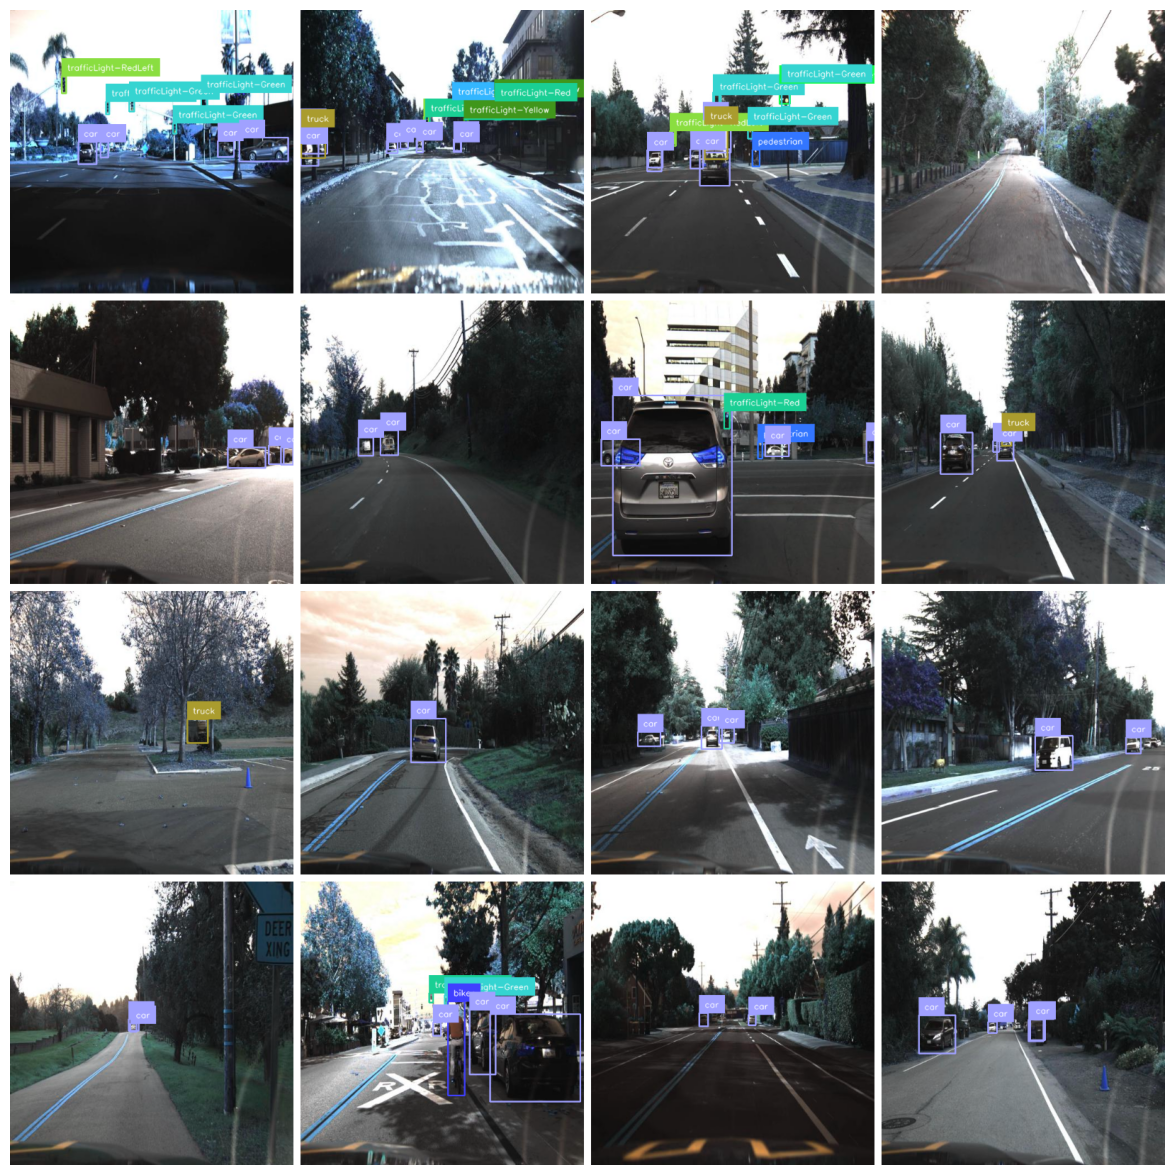

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 15))
plt.imshow(grid)
plt.axis('off')
plt.show()